Análisis espacio-temporal de la productividad primaria y la actividad pesquera aparente en Shiretoko, Japón

Notebook 01. Exploración del área de estudio

Objetivo: Identificar y explorar geográficamente el entorno marino de Shiretoko, ubicado al noreste de Hokkaido, Japón, como área de estudio para analizar la asociación espacio-temporal entre la productividad del ecosistema marino y la actividad pesquera aparente.

Actividades: 
*Identificar la ubicación geográfica de Shiretoko.
*Definir una delimitación preliminar del área de estudio.
*Representar geográficamente la zona.
*Identificar las coordenadas necesarias para consultar los datos de Copernicus Marine y Global Fishing Watch.

Fuentes de información previstas: 
- Copernicus Marine Service.
- Global Fishing Watch.

Integrantes: Isabel Pérez, Victor Gómez, María Alejandra Cifuentes y Keynie Cauich-Tome.

Proyecto: OceanHackWeek 2026.

In [1]:
import importlib.util

bibliotecas = [
    "pandas",
    "numpy",
    "matplotlib",
    "xarray",
    "geopandas",
    "cartopy",
    "scipy",
    "seaborn"
]

for biblioteca in bibliotecas:
    disponible = importlib.util.find_spec(biblioteca) is not None

    if disponible:
        print(biblioteca, "-> Disponible")
    else:
        print(biblioteca, "-> No instalada")

pandas -> Disponible
numpy -> Disponible
matplotlib -> Disponible
xarray -> Disponible
geopandas -> Disponible
cartopy -> Disponible
scipy -> Disponible
seaborn -> Disponible


In [2]:
# Bibliotecas para análisis y visualización geográfica

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import cartopy.crs as ccrs
import cartopy.feature as cfeature

print("Bibliotecas importadas correctamente")

Bibliotecas importadas correctamente


/srv/conda/envs/notebook/lib/python3.11/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_ocean.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/srv/conda/envs/notebook/lib/python3.11/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/srv/conda/envs/notebook/lib/python3.11/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/srv/conda/envs/notebook/lib/python3.11/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


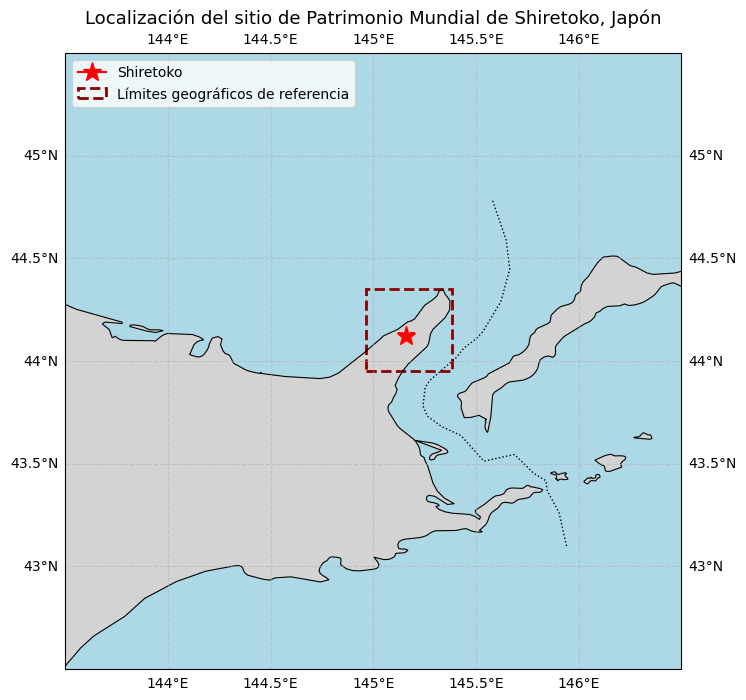

In [3]:
# Coordenadas oficiales de referencia del sitio Shiretoko
latitud_min = 43 + 57/60
latitud_max = 44 + 21/60

longitud_min = 144 + 58/60
longitud_max = 145 + 23/60

# Punto central aproximado del sitio
latitud_centro = 44.12306
longitud_centro = 145.16

# Crear el mapa
fig = plt.figure(figsize=(10, 8))

ax = plt.axes(projection=ccrs.PlateCarree())

# Extensión geográfica del mapa
ax.set_extent([143.5, 146.5, 42.5, 45.5])

# Agregar océano, tierra y costas
ax.add_feature(cfeature.OCEAN, facecolor="lightblue")
ax.add_feature(cfeature.LAND, facecolor="lightgray")
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle=":")

# Dibujar el punto central de Shiretoko
ax.plot(
    longitud_centro,
    latitud_centro,
    marker="*",
    color="red",
    markersize=14,
    transform=ccrs.PlateCarree(),
    label="Shiretoko"
)

# Dibujar el rectángulo envolvente de referencia
rectangulo = plt.Rectangle(
    (longitud_min, latitud_min),
    longitud_max - longitud_min,
    latitud_max - latitud_min,
    fill=False,
    edgecolor="darkred",
    linewidth=2,
    linestyle="--",
    transform=ccrs.PlateCarree(),
    label="Límites geográficos de referencia"
)

ax.add_patch(rectangulo)

# Agregar coordenadas
ax.gridlines(
    draw_labels=True,
    linestyle="--",
    alpha=0.5
)

plt.title(
    "Localización del sitio de Patrimonio Mundial de Shiretoko, Japón",
    fontsize=13
)

plt.legend(loc="upper left")
plt.show()